# SNR 3D — visualización del fenómeno (gráficas y animaciones 3D)

Notebook **de lectura**: la idea es *ver* la inestabilidad en 3D y entender qué se está
viendo. El análisis cuantitativo está en `SNR_3D_analisis.ipynb`; acá lo que hay es la
interfaz en tres dimensiones: cómo nace plana, cómo se rompe en dedos que caen (los dedos
de eyecta del remanente) y cómo el campo magnético la deja **alargada a lo largo de sus
líneas**.

**Recordatorio del montaje** (detalles en `Informe_SNR_3D.pdf`): fluido pesado arriba
($\rho_2=4$, la "eyecta"), ligero abajo ($\rho_1=1$, el "medio"), gravedad efectiva
$g=-0.01$, campo horizontal $\mathbf{B}=B_x\,\hat{x}$ (paralelo a la interfaz, como el
campo ambiental "drapado" en el choque de un SNR). Malla $48\times96\times48$,
16 salidas $t=0\ldots30$.

Qué produce este notebook:
1. **Dos envolventes 3D de la interfaz** (techos de burbujas y puntas de picos) en
   $t=15$ y $t=30$;
2. la **vista desde arriba** de los picos (donde la anisotropía se ve a simple vista)
   y su medida de elongación;
3. **Animación 1**: la evolución completa $t=0\to30$ en 3D (GIF);
4. **Animación 2**: un giro de cámara sobre el estado final, para apreciar el relieve
   (GIF).

Los GIF quedan además guardados en `figs/` para arrastrarlos a una presentación.

In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
import pyPLUTO as pp

RUN = "../pluto_run"
os.makedirs("figs", exist_ok=True)

sal = []
with open(os.path.join(RUN, "dbl.out")) as f:
    for line in f:
        p = line.split()
        sal.append((int(p[0]), float(p[1])))
sal.sort()
print("salidas:", [f"{n}:{t:.0f}" for n, t in sal])

def cargar(n):
    D = pp.Load(n, path=RUN)
    return D, D.x1, D.x2, D.x3

PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
salidas: ['0:0', '1:2', '2:4', '3:6', '4:8', '5:10', '6:12', '7:14', '8:16', '9:18', '10:20', '11:22', '12:24', '13:26', '14:28', '15:30']


## 1. Las dos envolventes de la interfaz

La superficie $\rho=2.5$ (el punto medio entre 1 y 4) ya no es un plano: con los dedos,
cada columna vertical puede cruzarla varias veces (el "sombrero" de una seta la cruza dos
veces). Para dibujar en 3D algo single-valuado usamos las **envolventes**:

* **techos** = primer cruce bajando desde arriba ($y\to-\infty$): el piso del fluido
  pesado, es decir las **burbujas** de fluido ligero que se cuelan subiendo;
* **puntas** = primer cruce subiendo desde abajo: los **picos** de fluido pesado que
  caen — en el mapeo SNR, **los dedos de eyecta penetrando el medio circundante**.

 Entre ambas queda atrapada toda la capa de mezcla (la que el notebook de análisis
 midió con su espesor $h_{95-5}$).

In [2]:
def envolventes(rho, x2, nivel=2.5):
    "primer cruce de 'nivel' desde abajo (puntas) y desde arriba (techos), por columna"
    f = rho - nivel                                   # (nx, ny, nz)
    chg = np.diff(np.sign(f), axis=1) != 0            # cambios de signo entre celdas en y
    def primero(bool_arr):
        hay = bool_arr.any(axis=1)
        idx = np.argmax(bool_arr, axis=1)             # primer True (0 si no hay ninguno)
        return np.where(hay, idx, -1)
    i_bajo = primero(chg)                             # puntas (desde abajo)
    i_alto = chg.shape[1] - 1 - primero(chg[:, ::-1, :])   # techos (desde arriba)
    def interp(idx):                                  # interpolacion lineal del cruce
        v = np.where(idx >= 0, idx, 0)                # (donde no hay cruce se tapa luego)
        f1 = np.take_along_axis(f, v[:, None, :], axis=1)[:, 0, :]
        f2 = np.take_along_axis(f, (v+1)[:, None, :], axis=1)[:, 0, :]
        frac = f1 / (f1 - f2)
        y = x2[v] + frac*(x2[v+1] - x2[v])
        return np.where(idx >= 0, y, np.nan)
    return interp(i_bajo), interp(i_alto)

# checkeo rapido en t=0: ambas envolventes deben coincidir (interfaz plana y=0)
D, x1, x2, x3 = cargar(sal[0][0])
p0, t0 = envolventes(np.asarray(D.rho), x2)
print(f"t=0: puntas ~ {np.nanmean(p0):+.3f} | techos ~ {np.nanmean(t0):+.3f}  (deben dar ~0)")

Load: folder ../pluto_run,     output 0


t=0: puntas ~ +0.000 | techos ~ +0.000  (deben dar ~0)


Load: folder ../pluto_run,     output 7


Load: folder ../pluto_run,     output 15


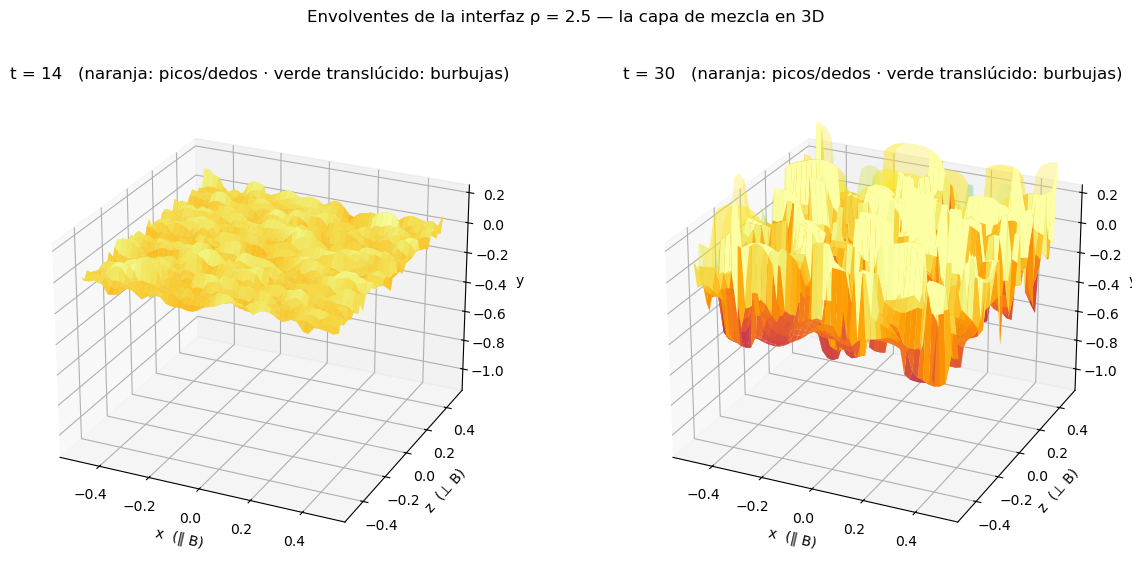

In [3]:
# Figura 1: las dos envolventes en t=15 y t=30
def superficie(ax, env, cmap, alpha=1.0, rstride=1, cstride=1):
    X, Z = np.meshgrid(x1, x3, indexing="ij")
    return ax.plot_surface(X, Z, env, cmap=cmap, alpha=alpha,
                           rstride=rstride, cstride=cstride,
                           vmin=-0.9, vmax=0.1, linewidth=0)

def estilo(ax, titulo):
    ax.set_xlabel("x  (‖ B)"); ax.set_ylabel("z  (⊥ B)"); ax.set_zlabel("y")
    ax.set_zlim(-1.15, 0.25)
    ax.view_init(elev=25, azim=-65)
    ax.set_title(titulo)

fig = plt.figure(figsize=(12.5, 5.6))
for k, n_obj in enumerate([7, 15]):          # t=14 y t=30
    D, x1, x2, x3 = cargar(n_obj)
    rho = np.asarray(D.rho)
    puntas, techos = envolventes(rho, x2)
    ax = fig.add_subplot(1, 2, k+1, projection="3d")
    superficie(ax, techos, "viridis", alpha=0.30)
    superficie(ax, puntas, "inferno", alpha=1.0)
    estilo(ax, f"t = {D.ntime:.0f}   (naranja: picos/dedos · verde translúcido: burbujas)")
fig.suptitle("Envolventes de la interfaz ρ = 2.5 — la capa de mezcla en 3D", y=1.02)
fig.tight_layout()
fig.savefig("figs/viz3d_envolventes.png", dpi=140, bbox_inches="tight")
plt.show()

**Qué fijarse en la figura de arriba.** Al principio (t=15, izquierda) la interfaz ya se
corrugó: bajan picos y suben burbujas. Al final (t=30, derecha) los picos son dedos largos
que penetran el fluido ligero — la imagen local de los dedos de eyecta de Tycho/Cas A.
Mira el relieve en planta: las crestas corren **a lo largo de $x$**, que es justo la
dirección del campo. No es casualidad: transversal al campo ($z$) crecen todos los modos
(intercambio), pero a lo largo del campo la tensión magnética solo deja pasar los modos
más largos que $\lambda_c=\chi^2L_x=0.04$ → la mezcla queda alisada en esa dirección.

## 2. Vista desde arriba + elongación de las estructuras

Si miramos las puntas desde arriba (un mapa de $y_\mathrm{int}(x,z)$) la anisotropía se
ve sin necesidad de 3D: franjas alargadas en $x$. Y se puede medir con una autocorrelación:
la distancia típica a lo largo de cada eje ($\ell_x$, $\ell_z$) es dónde la
autocorrelación de $y_\mathrm{int}-\langle y\rangle$ cae por debajo de $1/e$.

Load: folder ../pluto_run,     output 15


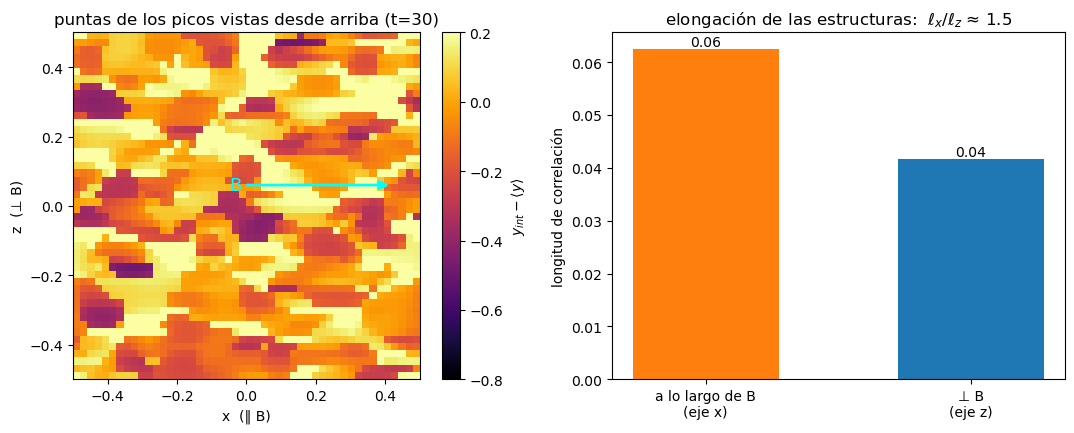

l_x = 0.063   l_z = 0.042   (razon 1.50: estructuras mas largas a lo largo de B)


In [4]:
D, x1, x2, x3 = cargar(sal[-1][0])
rho = np.asarray(D.rho)
puntas, _ = envolventes(rho, x2)
env = puntas - np.nanmean(puntas)
env = np.nan_to_num(env, nan=0.0)

fig, (ax, axb) = plt.subplots(1, 2, figsize=(11, 4.4))
im = ax.imshow(env.T, origin="lower", extent=[-0.5, 0.5, -0.5, 0.5],
               cmap="inferno", vmin=-0.8, vmax=0.2)
ax.set_xlabel("x  (‖ B)"); ax.set_ylabel("z  (⊥ B)")
ax.set_title(f"puntas de los picos vistas desde arriba (t={D.ntime:.0f})")
ax.annotate("B", xy=(0.42, 0.06), xytext=(-0.05, 0.06),
            arrowprops=dict(arrowstyle="-|>", color="cyan", lw=2),
            color="cyan", fontsize=13, va="center")
fig.colorbar(im, ax=ax, label=r"$y_{int}-\langle y\rangle$")

def long_corr(campo, eje):
    "desplazamiento donde la autocorrelacion cae bajo 1/e"
    c0 = np.mean(campo**2)
    L = campo.shape[eje]
    for lag in range(1, L//2):
        a = np.take(campo, range(0, L-lag), axis=eje)
        b = np.take(campo, range(lag, L), axis=eje)
        if np.mean(a*b)/c0 < np.exp(-1):
            return lag * (x1[1]-x1[0] if eje == 0 else x3[1]-x3[0])
    return np.nan
lx, lz = long_corr(env, 0), long_corr(env, 1)
axb.bar(["a lo largo de B\n(eje x)", "⊥ B\n(eje z)"], [lx, lz],
        color=["C1", "C0"], width=0.55)
axb.set_ylabel("longitud de correlación")
axb.set_title(rf"elongación de las estructuras:  $\ell_x/\ell_z$ ≈ {lx/lz:.1f}")
for i, v in enumerate([lx, lz]):
    axb.text(i, v, f"{v:.2f}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig("figs/viz3d_vista_superior.png", dpi=140)
plt.show()
print(f"l_x = {lx:.3f}   l_z = {lz:.3f}   (razon {lx/lz:.2f}: estructuras mas largas a lo largo de B)")

## 3. Animación 1: la evolución completa en 3D (t = 0 → 30)

Una peli de la interfaz: primero el plano apenas ondulado (fase lineal, crecimiento
exponencial con las tasas de la teoría), después los dedos compitiendo (fase no lineal:
los grandes se comen a los chicos) y al final una capa de mezcla saturada. La superficie
naranja son las **puntas** (dedos de eyecta); la verde translúcida, los techos de las
burbujas. La cámara está fija: el eje $x$ (dirección de $\mathbf{B}$) va de izquierda a
derecha.

In [5]:
# pre-extraemos las envolventes de TODAS las salidas (rapido y liviano en memoria)
frames = []
for n, t in sal:
    D, x1, x2, x3 = cargar(n)
    puntas, techos = envolventes(np.asarray(D.rho), x2)
    frames.append((t, puntas, techos))
print(f"{len(frames)} cuadros listos, t = {frames[0][0]:.0f} a {frames[-1][0]:.0f}")

fig = plt.figure(figsize=(6.8, 5.6))
ax = fig.add_subplot(111, projection="3d")
X, Z = np.meshgrid(x1, x3, indexing="ij")

def dibujo(i):
    ax.cla()
    t, puntas, techos = frames[i]
    ax.plot_surface(X, Z, techos, cmap="viridis", alpha=0.28,
                    vmin=-0.9, vmax=0.1, linewidth=0)
    ax.plot_surface(X, Z, puntas, cmap="inferno", alpha=1.0,
                    vmin=-0.9, vmax=0.1, linewidth=0)
    estilo(ax, f"evolución de la interfaz   t = {t:.0f}")
    return []

anim = FuncAnimation(fig, dibujo, frames=len(frames), interval=700, blit=False)
plt.close(fig)
anim.save("figs/anim_evolucion.gif", writer=PillowWriter(fps=2))
print("guardado: figs/anim_evolucion.gif")
HTML(anim.to_jshtml(fps=2))

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 1


Load: folder ../pluto_run,     output 2


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 4


Load: folder ../pluto_run,     output 5


... (8 outputs left out)

Load: folder ../pluto_run,     output 14


Load: folder ../pluto_run,     output 15


16 cuadros listos, t = 0 a 30


guardado: figs/anim_evolucion.gif


**Cómo leer la animación.** (1) En los primeros cuadros no pasa casi nada visible: la
semilla aleatoria tiene amplitud $10^{-2}$ y crece exponencialmente — la teoría dice
$e^{\sigma t}$ con $\sigma$ entre 0.19 y 0.49, así que entre t=0 y t=6 la interfaz solo
amplitúa el ruido. (2) Entre t~8 y t~16 los dedos ganan relieve rápido: es la fase que el
notebook de análisis midió ($\sigma_\mathrm{eff}=0.229$). (3) Al final los dedos grandes
dominan y la capa satura: fusión de modos, ya no vale el crecimiento exponencial.

## 4. Animación 2: giro de cámara sobre el estado final

El mismo estado final (t=30) girando 360°. Sirve para apreciar que los dedos no son
cilindros: son **cresta/hojas alargadas en la dirección del campo** (el eje que apunta
hacia el observador al inicio). Esa es la huella geométrica de que los modos de
intercambio ($\mathbf{k}\perp\mathbf{B}$) crecieron libres mientras los undulares
($\mathbf{k}\parallel\mathbf{B}$) cortos estaban frenados.

In [6]:
t_final, puntas, techos = frames[-1]
fig = plt.figure(figsize=(6.8, 5.6))
ax = fig.add_subplot(111, projection="3d")

def gira(k):
    ax.cla()
    ax.plot_surface(X, Z, techos, cmap="viridis", alpha=0.28,
                    vmin=-0.9, vmax=0.1, linewidth=0)
    ax.plot_surface(X, Z, puntas, cmap="inferno", alpha=1.0,
                    vmin=-0.9, vmax=0.1, linewidth=0)
    estilo(ax, f"t = {t_final:.0f} — giro de cámara")
    ax.view_init(elev=25, azim=-65 + k*15)
    return []

anim2 = FuncAnimation(fig, gira, frames=24, interval=180, blit=False)
plt.close(fig)
anim2.save("figs/anim_turntable.gif", writer=PillowWriter(fps=10))
print("guardado: figs/anim_turntable.gif")
HTML(anim2.to_jshtml(fps=10))

guardado: figs/anim_turntable.gif


## 5. Cómo se conecta esto con los números del análisis

| Lo que se VE acá | El número que lo mide (notebook de análisis) |
|---|---|
| dedos que ganan relieve entre t~8 y t~16 | $\sigma_\mathrm{eff}=0.229$ (teoría 0.19–0.49) |
| crestas alargadas en $x$ (‖ B) | $P_\perp/P_\parallel\approx17$ en el espectro; $\ell_x/\ell_z>1$ arriba |
| puntas que se clavan y techos que suben | espesor de mezcla $h_{95-5}(t)$ |
| nada explota ni degenera en la corrida | energía conservada a $7\times10^{-11}$ |

**Limitaciones honestas de la visualización**: las envolventes solo muestran la primera
cruce desde cada lado — las "setas" (hongos con voladizo) y las hojas intermedias de la
mezcla quedan escondidas entre las dos superficies. Para ver la superficie completa
habría que hacer una isosuperficie (marching cubes, `scikit-image`), que no está instalada
en este entorno. Y recordar la resolución: $\lambda_c=0.04\approx2$ celdas, o sea que
esta malla no puede mostrar estructura más fina que eso (ver el informe, §limitaciones).

**Archivos generados** (en `figs/`, listos para una presentación): `viz3d_envolventes.png`,
`viz3d_vista_superior.png`, `anim_evolucion.gif`, `anim_turntable.gif`. Para explorar
cortes en vivo interactivos está la GUI que viene con py-pluto (`pypluto-gui`).